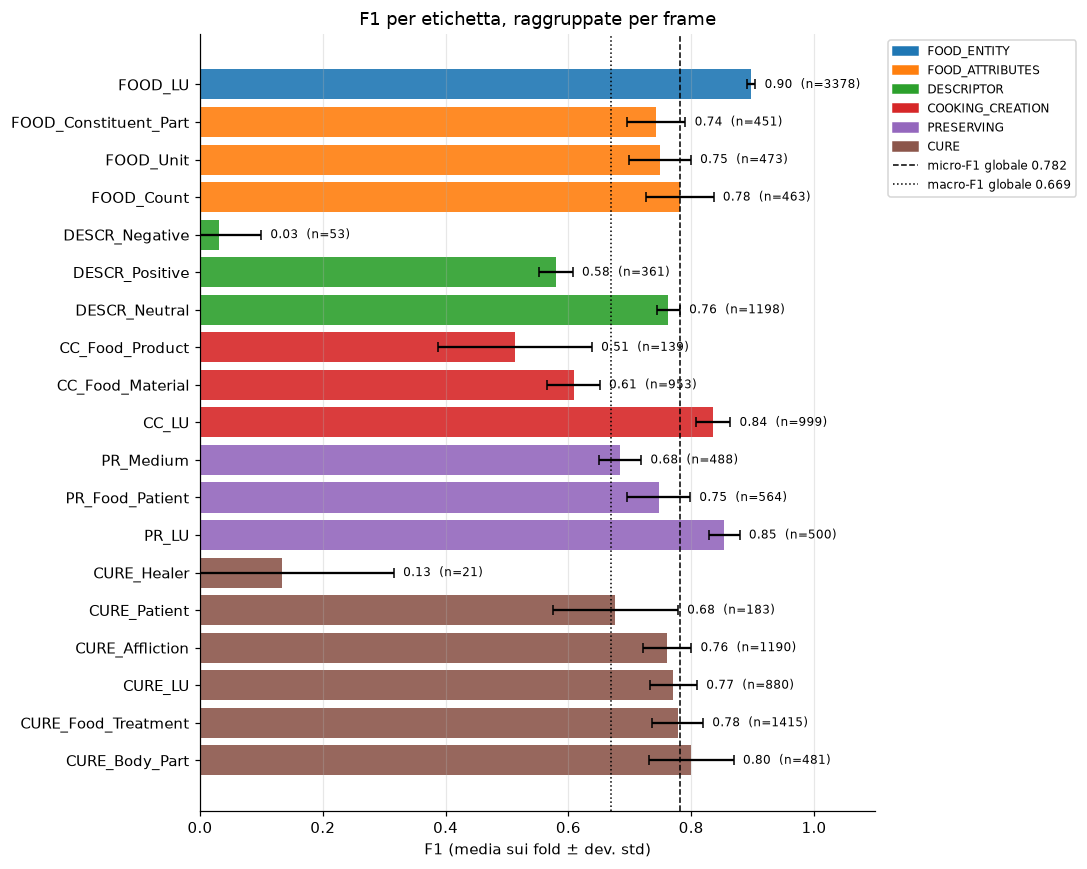

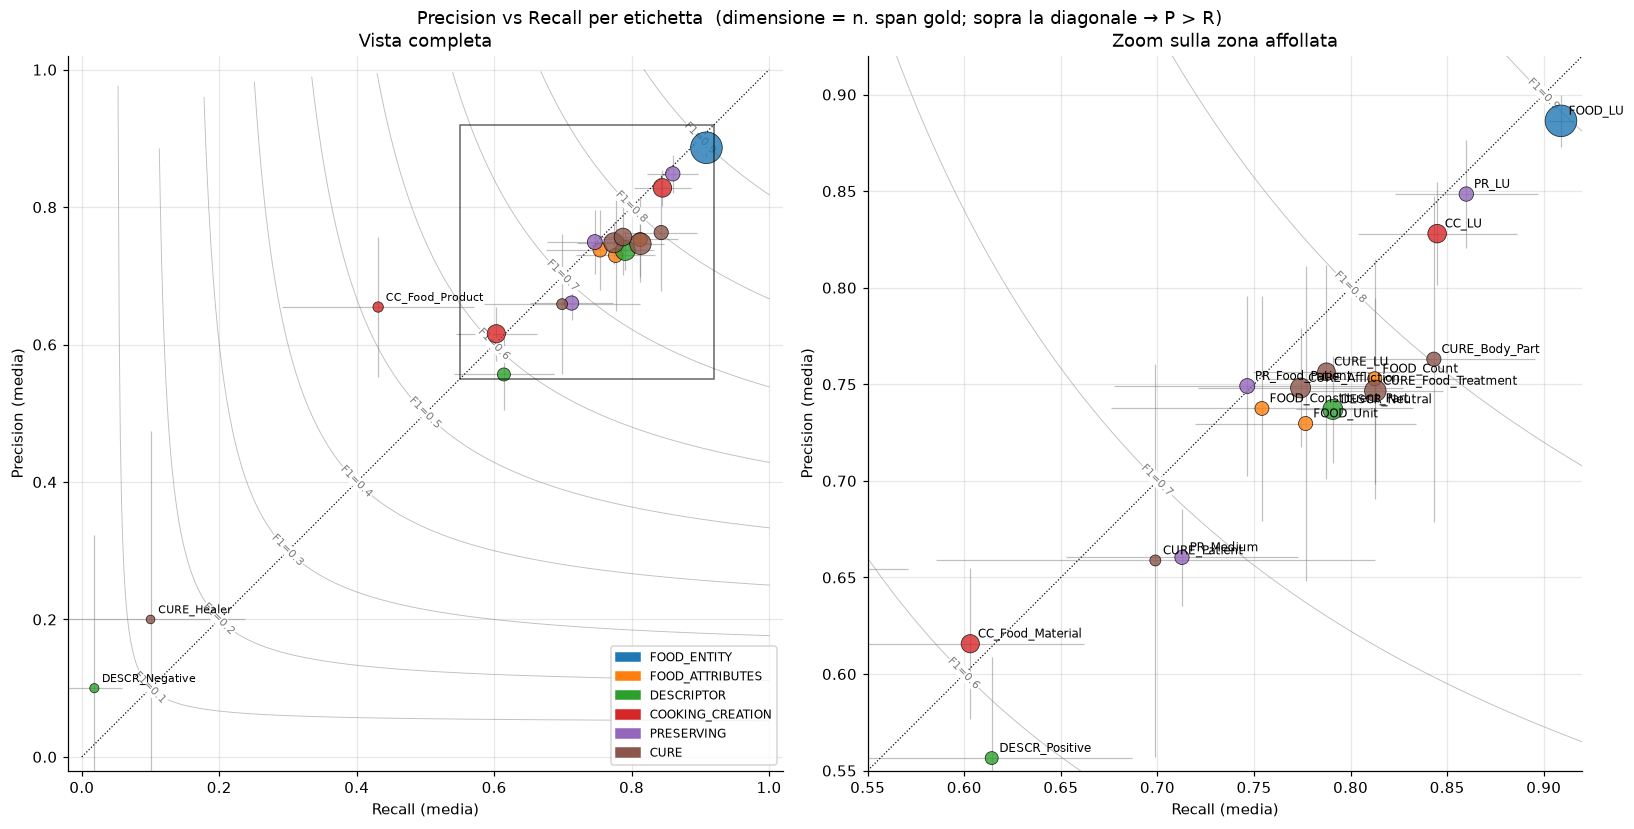

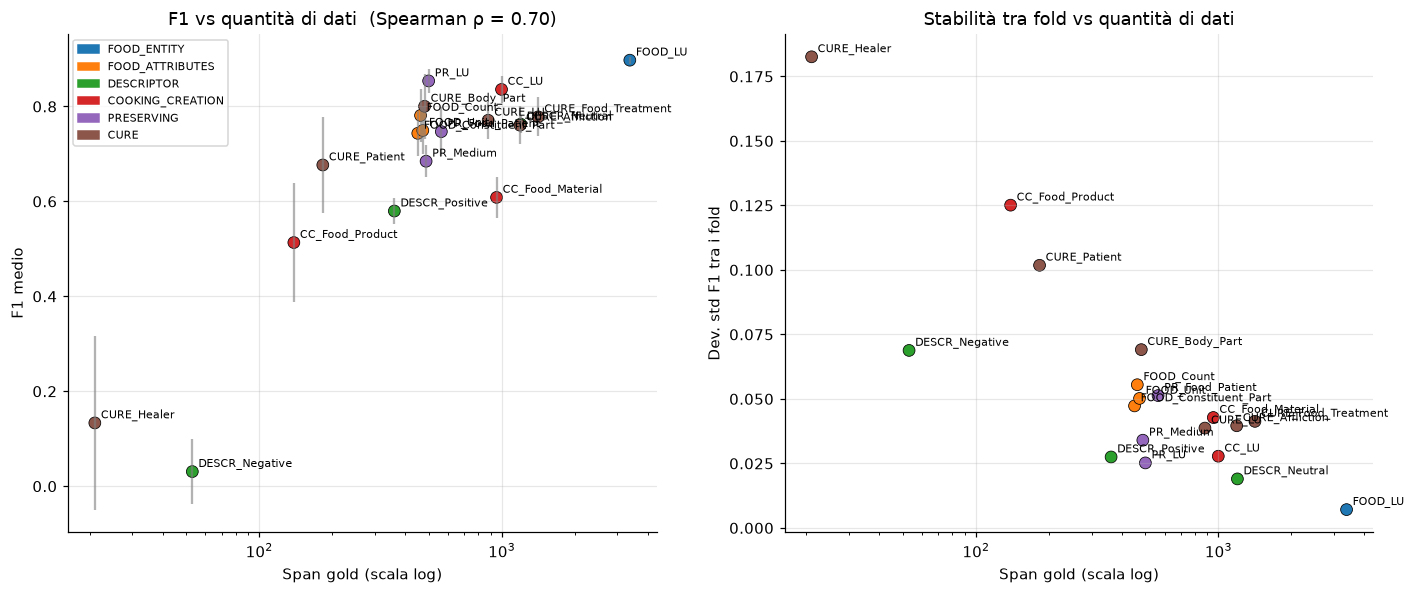

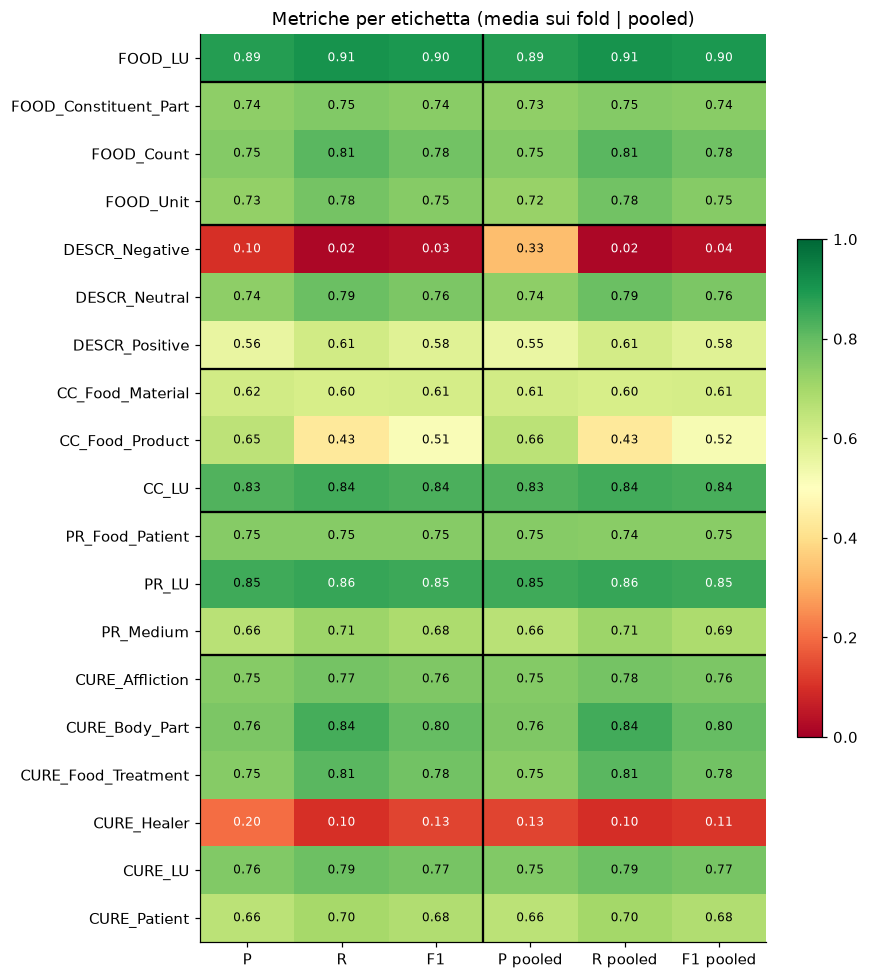

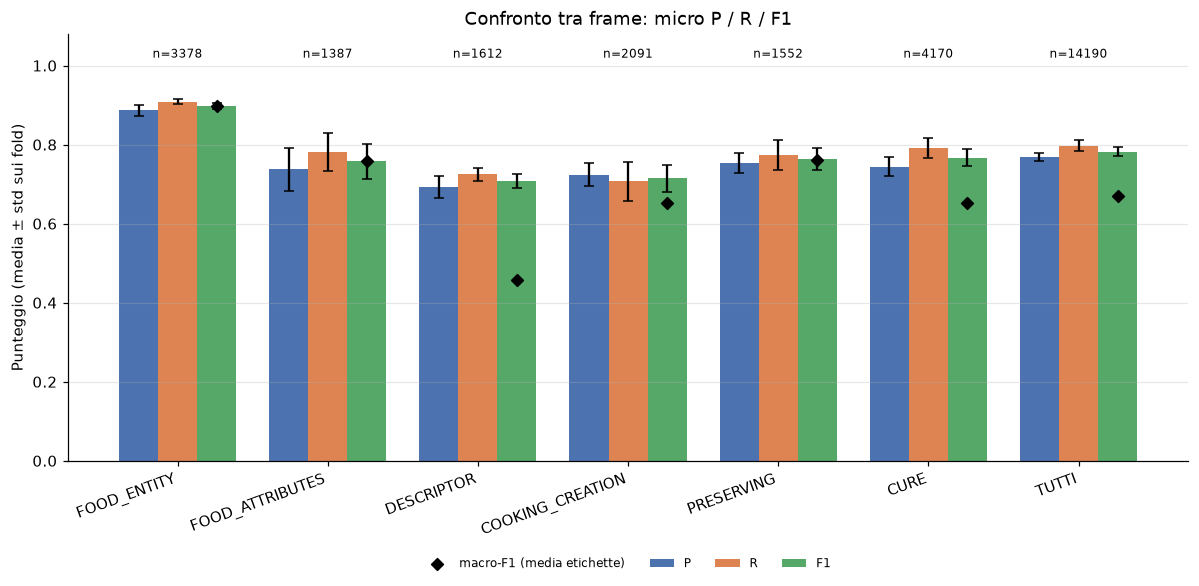

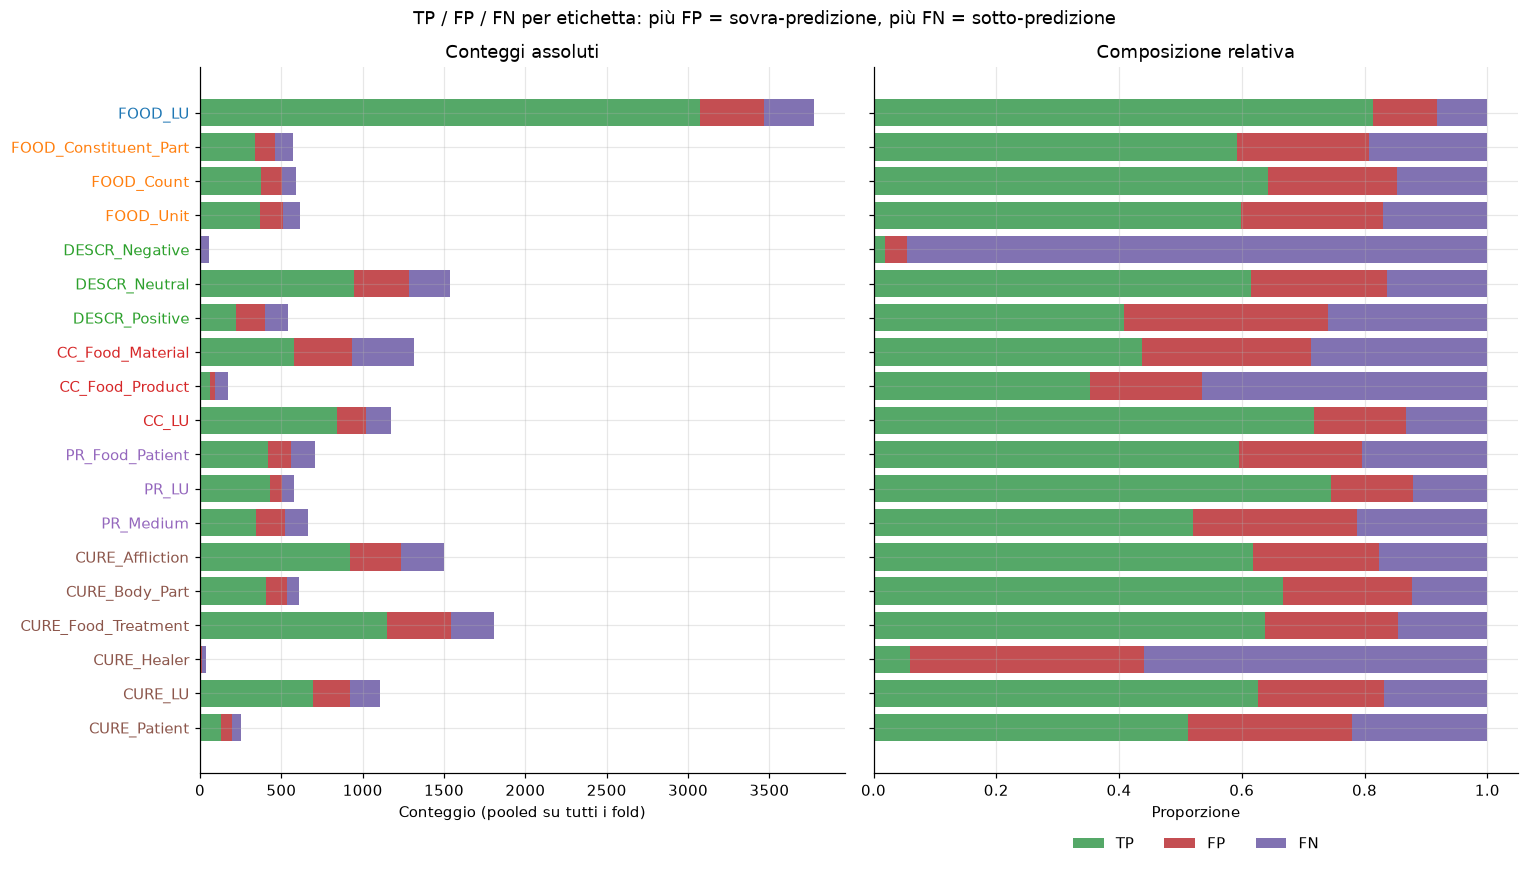

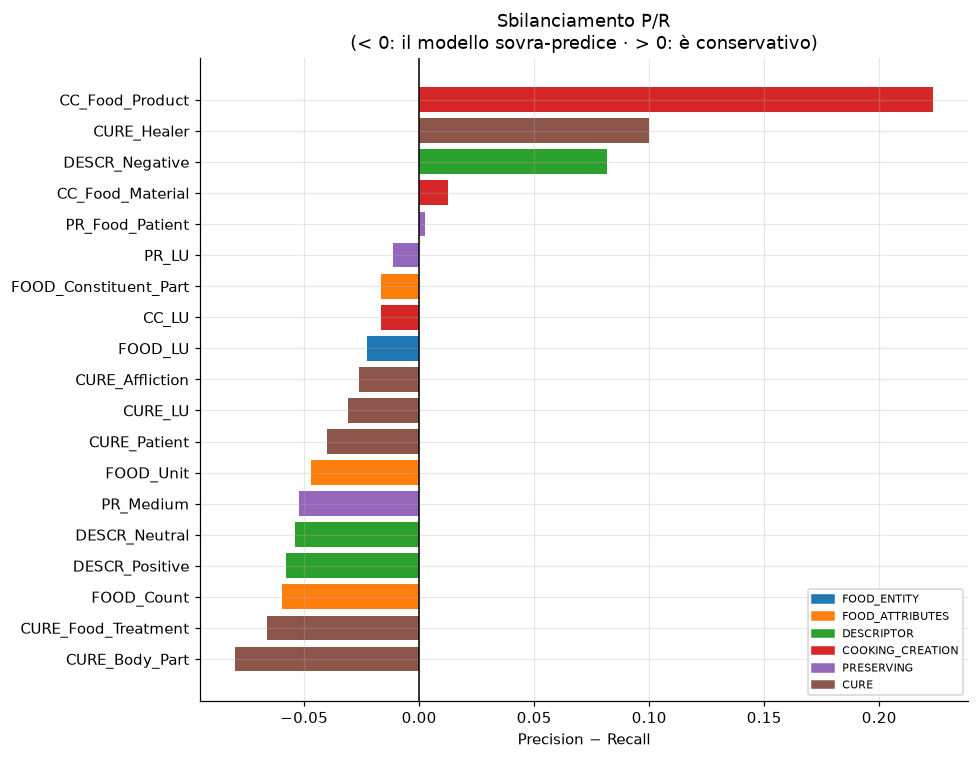

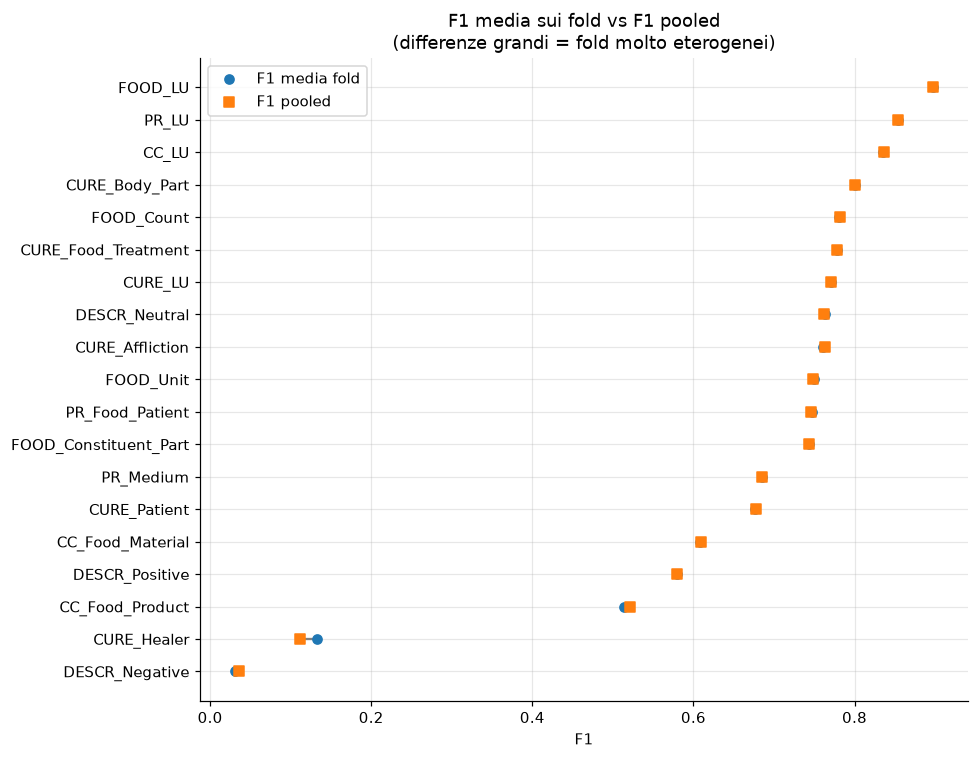

In [2]:
#!/usr/bin/env python3
"""
Visualizzazione dei risultati di cross-validation (cv_summary.tsv).

Uso:
    python visualizza_cv.py cv_summary.tsv [cartella_output]

Genera un PNG per ogni grafico e un PDF unico con tutte le figure.
"""
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import Patch

# ------------------------------------------------------------------ dati
path = "/Users/teresapaccosi/Desktop/food_trifecta_pipeline/cv_summary_macberth_multi.tsv"
# outdir = "figure_cv"
# outdir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(path, sep="\t")

labels = df[~df["label"].isin(["<micro>", "<macro>"])].copy()      # singole etichette
frames = df[(df["label"] == "<micro>") & (df["frame"] != "<ALL>")].copy()  # micro per frame
all_micro = df[(df["frame"] == "<ALL>") & (df["label"] == "<micro>")].iloc[0]
all_macro = df[(df["frame"] == "<ALL>") & (df["label"] == "<macro>")].iloc[0]

frame_order = list(dict.fromkeys(labels["frame"]))
palette = plt.get_cmap("tab10")
fcolor = {f: palette(i) for i, f in enumerate(frame_order)}
labels["color"] = labels["frame"].map(fcolor)


def short(lbl: str) -> str:
    """Accorcia i nomi lunghi per gli assi."""
    return lbl.replace("COOKING_CREATION_", "CC_")


labels["short"] = labels["label"].map(short)
legend_frames = [Patch(color=fcolor[f], label=f) for f in frame_order]

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
figs = []


def save(fig, name):
    fig.tight_layout()
    # fig.savefig(outdir / f"{name}.png", dpi=200, bbox_inches="tight")
    figs.append(fig)


# ------------------------------------------- 1. F1 per etichetta (± std)
d = labels.sort_values(["frame", "F1_mean"], key=lambda s: s.map(frame_order.index)
                       if s.name == "frame" else s)
fig, ax = plt.subplots(figsize=(10, 8))
y = np.arange(len(d))
ax.barh(y, d["F1_mean"], xerr=d["F1_std"], color=d["color"], capsize=3, alpha=0.9)
for yi, (f1, sd, n) in enumerate(zip(d["F1_mean"], d["F1_std"], d["gold_spans"])):
    ax.text(f1 + sd + 0.015, yi, f"{f1:.2f}  (n={int(n)})", va="center", fontsize=8)
ax.set_yticks(y, d["short"])
ax.invert_yaxis()
ax.axvline(all_micro["F1_mean"], ls="--", c="k", lw=1, label=f"micro-F1 globale {all_micro['F1_mean']:.3f}")
ax.axvline(all_macro["F1_mean"], ls=":", c="k", lw=1, label=f"macro-F1 globale {all_macro['F1_mean']:.3f}")
ax.set_xlim(0, 1.1)
ax.set_xlabel("F1 (media sui fold ± dev. std)")
ax.set_title("F1 per etichetta, raggruppate per frame")
ax.grid(axis="y", visible=False)
ax.legend(handles=legend_frames + ax.get_legend_handles_labels()[0],
          loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
save(fig, "01_f1_per_etichetta")

# ------------------------------------------- 2. Precision vs Recall
def pr_panel(ax, lims, label_size, skip_box=None):
    # isolinee di F1: P = F1*R / (2R - F1)
    r = np.linspace(0.001, 1, 600)
    for f in np.arange(0.1, 1.0, 0.1):
        pp = f * r / (2 * r - f)
        m = (r > f / 2) & (pp > 0) & (pp <= 1)
        ax.plot(r[m], pp[m], c="grey", lw=0.6, alpha=0.5)
        i = np.argmin(np.abs(r[m] - pp[m]))          # etichetta sulla diagonale
        if lims[0] <= r[m][i] <= lims[1]:
            ax.text(r[m][i], pp[m][i], f"F1={f:.1f}", fontsize=7, color="grey",
                    rotation=-45, ha="center", va="center",
                    bbox=dict(fc="white", ec="none", pad=0.5))
    sizes = 30 + 400 * labels["gold_spans"] / labels["gold_spans"].max()
    ax.errorbar(labels["R_mean"], labels["P_mean"], xerr=labels["R_std"], yerr=labels["P_std"],
                fmt="none", ecolor="grey", alpha=0.5, lw=0.8)
    ax.scatter(labels["R_mean"], labels["P_mean"], s=sizes, c=labels["color"],
               alpha=0.8, edgecolor="k", lw=0.5, zorder=3)
    for _, r_ in labels.iterrows():
        inside = lims[0] <= r_["R_mean"] <= lims[1] and lims[0] <= r_["P_mean"] <= lims[1]
        in_zoom = skip_box and all(skip_box[0] <= v <= skip_box[1] for v in (r_["R_mean"], r_["P_mean"]))
        if inside and not in_zoom:
            ax.annotate(r_["short"], (r_["R_mean"], r_["P_mean"]), fontsize=label_size,
                        xytext=(5, 4), textcoords="offset points")
    ax.plot([0, 1], [0, 1], "k:", lw=0.8)
    ax.set_xlim(*lims)
    ax.set_ylim(*lims)
    ax.set_aspect("equal")
    ax.set_xlabel("Recall (media)")
    ax.set_ylabel("Precision (media)")


fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
pr_panel(axes[0], (-0.02, 1.02), 7, skip_box=(0.55, 0.92))
axes[0].set_title("Vista completa")
pr_panel(axes[1], (0.55, 0.92), 8)
axes[1].set_title("Zoom sulla zona affollata")
axes[0].indicate_inset((0.55, 0.55, 0.37, 0.37), edgecolor="k", alpha=0.6)
axes[0].legend(handles=legend_frames, fontsize=8, loc="lower right")
fig.suptitle("Precision vs Recall per etichetta  (dimensione = n. span gold; "
             "sopra la diagonale → P > R)")
save(fig, "02_precision_vs_recall")

# ------------------------------------------- 3. F1 vs supporto
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
ax = axes[0]
ax.scatter(labels["gold_spans"], labels["F1_mean"], c=labels["color"], s=60, edgecolor="k", lw=0.5)
ax.errorbar(labels["gold_spans"], labels["F1_mean"], yerr=labels["F1_std"],
            fmt="none", ecolor="grey", alpha=0.6)
for _, r_ in labels.iterrows():
    ax.annotate(r_["short"], (r_["gold_spans"], r_["F1_mean"]), fontsize=7,
                xytext=(4, 3), textcoords="offset points")
rho = labels[["gold_spans", "F1_mean"]].corr(method="spearman").iloc[0, 1]
ax.set_xscale("log")
ax.set_xlabel("Span gold (scala log)")
ax.set_ylabel("F1 medio")
ax.set_title(f"F1 vs quantità di dati  (Spearman ρ = {rho:.2f})")
ax.legend(handles=legend_frames, fontsize=7)

ax = axes[1]
ax.scatter(labels["gold_spans"], labels["F1_std"], c=labels["color"], s=60, edgecolor="k", lw=0.5)
for _, r_ in labels.iterrows():
    ax.annotate(r_["short"], (r_["gold_spans"], r_["F1_std"]), fontsize=7,
                xytext=(4, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("Span gold (scala log)")
ax.set_ylabel("Dev. std F1 tra i fold")
ax.set_title("Stabilità tra fold vs quantità di dati")
save(fig, "03_f1_vs_supporto")

# ------------------------------------------- 4. Heatmap P / R / F1
d = labels.set_index("short")[["P_mean", "R_mean", "F1_mean", "P_pooled", "R_pooled", "F1_pooled"]]
fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(d.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(d.shape[1]), ["P", "R", "F1", "P pooled", "R pooled", "F1 pooled"])
ax.set_yticks(range(d.shape[0]), d.index)
ax.grid(False)
for i in range(d.shape[0]):
    for j in range(d.shape[1]):
        v = d.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if v < 0.25 or v > 0.85 else "black")
# separatori tra frame
bounds = labels.reset_index(drop=True).groupby("frame", sort=False).size().cumsum().values[:-1]
for b in bounds:
    ax.axhline(b - 0.5, c="k", lw=1.5)
ax.axvline(2.5, c="k", lw=1.5)
fig.colorbar(im, ax=ax, fraction=0.04)
ax.set_title("Metriche per etichetta (media sui fold | pooled)")
save(fig, "04_heatmap_metriche")

# ------------------------------------------- 5. Confronto tra frame (micro)
d = pd.concat([frames, all_micro.to_frame().T])
d["frame"] = d["frame"].replace({"<ALL>": "TUTTI"})
x = np.arange(len(d))
w = 0.26
fig, ax = plt.subplots(figsize=(11, 5.5))
for k, (m, col) in enumerate([("P", "#4C72B0"), ("R", "#DD8452"), ("F1", "#55A868")]):
    ax.bar(x + (k - 1) * w, d[f"{m}_mean"].astype(float), w, yerr=d[f"{m}_std"].astype(float),
           capsize=3, label=m, color=col)
# macro-F1 per frame (media semplice delle etichette)
macro_f = labels.groupby("frame", sort=False)["F1_mean"].mean()
macro_vals = [macro_f.get(f, all_macro["F1_mean"]) for f in d["frame"].replace({"TUTTI": "<ALL>"})]
ax.scatter(x + w, macro_vals, marker="D", c="k", zorder=5, s=30, label="macro-F1 (media etichette)")
for xi, n in zip(x, d["gold_spans"]):
    ax.text(xi, 1.02, f"n={int(n)}", ha="center", fontsize=8)
ax.set_xticks(x, d["frame"], rotation=20, ha="right")
ax.set_ylim(0, 1.08)
ax.set_ylabel("Punteggio (media ± std sui fold)")
ax.set_title("Confronto tra frame: micro P / R / F1")
ax.grid(axis="x", visible=False)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, frameon=False)
save(fig, "05_confronto_frame")

# ------------------------------------------- 6. Composizione errori TP/FP/FN
d = labels.iloc[::-1]
tot = d[["tp", "fp", "fn"]].sum(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
y = np.arange(len(d))
for ax, norm in zip(axes, [False, True]):
    left = np.zeros(len(d))
    for c, col, lab in [("tp", "#55A868", "TP"), ("fp", "#C44E52", "FP"), ("fn", "#8172B2", "FN")]:
        vals = d[c].values / (tot.values if norm else 1)
        ax.barh(y, vals, left=left, color=col, label=lab)
        left += vals
    ax.set_xlabel("Proporzione" if norm else "Conteggio (pooled su tutti i fold)")
    ax.set_title("Composizione relativa" if norm else "Conteggi assoluti")
axes[0].set_yticks(y, d["short"])
for t, c in zip(axes[0].get_yticklabels(), d["color"]):
    t.set_color(c)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=3, frameon=False)
fig.suptitle("TP / FP / FN per etichetta: più FP = sovra-predizione, più FN = sotto-predizione")
save(fig, "06_composizione_errori")

# ------------------------------------------- 7. Bias predittivo (P − R)
d = labels.assign(diff=labels["P_mean"] - labels["R_mean"]).sort_values("diff")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(d["short"], d["diff"], color=d["color"])
ax.axvline(0, c="k", lw=1)
ax.set_xlabel("Precision − Recall")
ax.set_title("Sbilanciamento P/R\n(< 0: il modello sovra-predice · > 0: è conservativo)")
ax.legend(handles=legend_frames, fontsize=7, loc="lower right")
save(fig, "07_bias_precision_recall")

# ------------------------------------------- 8. Media sui fold vs pooled
d = labels.sort_values("F1_mean")
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(d))
ax.hlines(y, d["F1_mean"], d["F1_pooled"], color="grey")
ax.scatter(d["F1_mean"], y, label="F1 media fold", zorder=3)
ax.scatter(d["F1_pooled"], y, label="F1 pooled", marker="s", zorder=3)
ax.set_yticks(y, d["short"])
ax.set_xlabel("F1")
ax.set_title("F1 media sui fold vs F1 pooled\n(differenze grandi = fold molto eterogenei)")
ax.legend()
save(fig, "08_mean_vs_pooled")

# ------------------------------------------------------------------ PDF
# with PdfPages(outdir / "report_cv.pdf") as pdf:
#     for f in figs:
#         pdf.savefig(f, bbox_inches="tight")

# print(f"Salvate {len(figs)} figure in {outdir.resolve()}")
if "--show" in sys.argv:
    plt.show()